# BookFlow - İlk veri kontrolü
Bu notebook analiz içindir; Streamlit dashboard ayrı `.py` dosyasında çalışır.

In [3]:
from pathlib import Path
import pandas as pd
data_path = Path("data/B2B_Transaction_Data_.xlsx")
assert data_path.exists(), "Excel dosyasını data klasörüne koyun."
df = pd.read_excel(data_path, engine="openpyxl")
print("Boyut:", df.shape)
display(df.head())

Boyut: (664154, 10)


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
0,BSR202000000027,A02348,2020-01-02,8698543133198,Anatolian Puzzle Dünya Siyasi Harita (3319),1000 Parça Puzzle,ISTANBUL,1.0,18.92,22.8
1,BSR202000000007,A02212,2020-01-02,8698543110793,Anatolian-Puzzle 1000 Kurt Timi,1000 Parça Puzzle,ISTANBUL,1.0,29.84,37.3
2,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.0,29.84,37.3
3,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.0,29.84,37.3
4,BAD202000000028,A00905,2020-01-02,8698543110335,Gezegenler (Puzzle 1000) 1033,1000 Parça Puzzle,AYDIN,1.0,29.84,37.3


In [4]:
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing_count"))
print("InvoiceNo benzersiz:", df["InvoiceNo"].nunique())
print("CustomerID benzersiz:", df["CustomerID"].nunique())

,dtype
InvoiceNo,str
CustomerID,str
InvoiceDate,str
StockCode,int64
Description,object
Category,str
City,str
Quantity,float64
NetPrice,float64
UnitPrice,float64


,missing_count
InvoiceNo,0
CustomerID,0
InvoiceDate,0
StockCode,0
Description,0
Category,64
City,6802
Quantity,6
NetPrice,0
UnitPrice,0


InvoiceNo benzersiz: 47471
CustomerID benzersiz: 1202


**Sonraki kontrol:** `NetPrice` birim fiyat mı, fatura satırı toplamı mı? Bunu doğrulamadan revenue hesaplamayın.

In [6]:

import pandas as pd
import numpy as np

df = pd.read_excel("data/B2B_Transaction_Data_.xlsx")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (664154, 10)


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
0,BSR202000000027,A02348,2020-01-02,8698543133198,Anatolian Puzzle Dünya Siyasi Harita (3319),1000 Parça Puzzle,ISTANBUL,1.0,18.92,22.8
1,BSR202000000007,A02212,2020-01-02,8698543110793,Anatolian-Puzzle 1000 Kurt Timi,1000 Parça Puzzle,ISTANBUL,1.0,29.84,37.3
2,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.0,29.84,37.3
3,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.0,29.84,37.3
4,BAD202000000028,A00905,2020-01-02,8698543110335,Gezegenler (Puzzle 1000) 1033,1000 Parça Puzzle,AYDIN,1.0,29.84,37.3


In [7]:

df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nData types:")
print(df.dtypes)


<class 'pandas.DataFrame'>
RangeIndex: 664154 entries, 0 to 664153
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    664154 non-null  str    
 1   CustomerID   664154 non-null  str    
 2   InvoiceDate  664154 non-null  str    
 3   StockCode    664154 non-null  int64  
 4   Description  664154 non-null  object 
 5   Category     664090 non-null  str    
 6   City         657352 non-null  str    
 7   Quantity     664148 non-null  float64
 8   NetPrice     664154 non-null  float64
 9   UnitPrice    664154 non-null  float64
dtypes: float64(3), int64(1), object(1), str(5)
memory usage: 85.0+ MB

Missing values:
InvoiceNo         0
CustomerID        0
InvoiceDate       0
StockCode         0
Description       0
Category         64
City           6802
Quantity          6
NetPrice          0
UnitPrice         0
dtype: int64

Data types:
InvoiceNo          str
CustomerID         str
InvoiceDate        str
S

In [8]:

df_clean = df.copy()

# Tarih formatı
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Sayısal sütunlar
numeric_cols = ["Quantity", "NetPrice", "UnitPrice"]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# NULL gibi metinleri eksik değer olarak yorumla
df_clean["City"] = df_clean["City"].replace(
    ["NULL", "", "nan"], np.nan
)

# Eksik ve hatalı miktarları ayır
invalid_rows = df_clean[
    df_clean["InvoiceDate"].isna()
    | df_clean["Quantity"].isna()
    | df_clean["NetPrice"].isna()
    | df_clean["UnitPrice"].isna()
].copy()

# Analiz için sayısal alanları geçerli satırları tut
df_clean = df_clean.dropna(
    subset=["InvoiceDate", "Quantity",
            "NetPrice", "UnitPrice"]
)

# Pozitif miktar ve fiyatlı satış işlemleri
df_sales = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["NetPrice"] > 0)
].copy()

print("Original rows:", len(df))
print("Invalid numeric/date rows:", len(invalid_rows))
print("Valid sales rows:", len(df_sales))


Original rows: 664154
Invalid numeric/date rows: 6
Valid sales rows: 664138


In [9]:

df_sales["Revenue"] = (
    df_sales["Quantity"] * df_sales["NetPrice"]
)

# Aylık analiz için
df_sales["Month"] = (
    df_sales["InvoiceDate"].dt.to_period("M")
)

print("Total sales revenue:",
      round(df_sales["Revenue"].sum(), 2))


Total sales revenue: 29579960.23


In [10]:

total_revenue = df_sales["Revenue"].sum()
total_orders = df_sales["InvoiceNo"].nunique()
total_customers = df_sales["CustomerID"].nunique()
total_products = df_sales["StockCode"].nunique()
total_quantity = df_sales["Quantity"].sum()

avg_order_value = total_revenue / total_orders

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")
print(f"Total Quantity: {total_quantity:,.0f}")
print(f"Average Order Value: {avg_order_value:,.2f}")


Total Revenue: 29,579,960.23
Total Orders: 47,468
Total Customers: 1,201
Total Products: 43,576
Total Quantity: 1,889,107
Average Order Value: 623.16


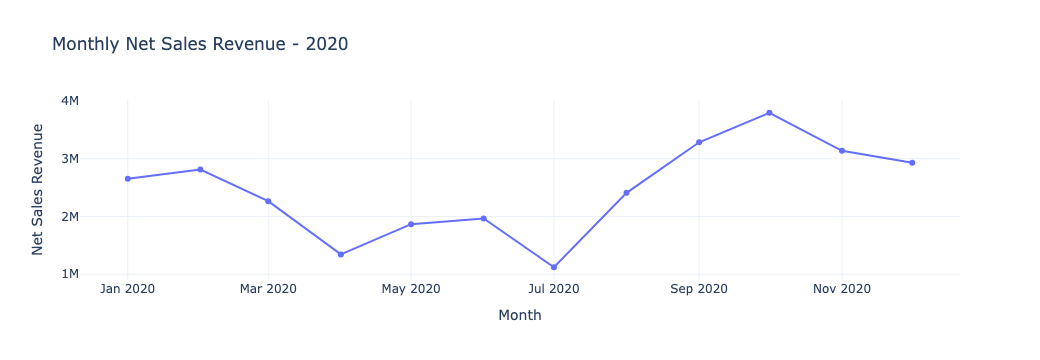

In [11]:

import plotly.express as px

monthly_sales = (
    df_sales.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

monthly_sales["Month"] = (
    monthly_sales["Month"].astype(str)
)

fig = px.line(
    monthly_sales,
    x="Month",
    y="Revenue",
    markers=True,
    title="Monthly Net Sales Revenue - 2020"
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Net Sales Revenue",
    template="plotly_white"
)

fig.show()


In [14]:

# Ürün bazında toplam satış değeri
product_sales = (
    df_sales.groupby("StockCode", as_index=False)
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
)

# En yüksek satış değerinden düşüğe sırala
product_sales = product_sales.sort_values(
    "Total_Revenue", ascending=False
).reset_index(drop=True)

# Kümülatif satış oranı
product_sales["Cumulative_Revenue"] = (
    product_sales["Total_Revenue"].cumsum()
)

total_revenue = product_sales["Total_Revenue"].sum()

product_sales["Cumulative_Percentage"] = (
    product_sales["Cumulative_Revenue"]
    / total_revenue * 100
)

# ABC sınıflandırması
# Sınırı geçen ürün de ilgili sınıfa dahil edilir
previous_percentage = (
    product_sales["Cumulative_Percentage"]
    - product_sales["Total_Revenue"] / total_revenue * 100
)

product_sales["ABC_Class"] = np.select(
    [
        previous_percentage < 80,
        previous_percentage < 95
    ],
    ["A", "B"],
    default="C"
)

display(product_sales.head(10))


,StockCode,Total_Revenue,Total_Quantity,Cumulative_Revenue,Cumulative_Percentage,ABC_Class
0,9786058213241,478576.548226,22850.0,4.785765e+05,1.617908,A
1,9786058422841,201214.900000,9101.0,6.797914e+05,2.298149,A
2,9786056883569,182617.760000,8400.0,8.624092e+05,2.915518,A
3,9789754054453,165152.409998,13612.0,1.027562e+06,3.473844,A
4,9789752430990,149732.088950,8948.0,1.177294e+06,3.980038,A
5,9789754056839,140424.209981,11425.0,1.317718e+06,4.454766,A
6,9789752124394,137823.260000,8246.0,1.455541e+06,4.920700,A
7,9789750738609,130810.299999,8595.0,1.586351e+06,5.362926,A
8,9786059952767,117385.350000,7624.0,1.703737e+06,5.759767,A
9,9786059952750,116216.912436,7535.0,1.819954e+06,6.152658,A


In [15]:

abc_summary = (
    product_sales.groupby("ABC_Class")
    .agg(
        Product_Count=("StockCode", "count"),
        Total_Revenue=("Total_Revenue", "sum")
    )
    .reset_index()
)

abc_summary["Revenue_Share_%"] = (
    abc_summary["Total_Revenue"]
    / abc_summary["Total_Revenue"].sum() * 100
)

abc_summary["Product_Share_%"] = (
    abc_summary["Product_Count"]
    / abc_summary["Product_Count"].sum() * 100
)

display(abc_summary.round(2))


,ABC_Class,Product_Count,Total_Revenue,Revenue_Share_%,Product_Share_%
0,A,3398,23664409.19,80.0,7.80
1,B,10802,4436682.03,15.0,24.79
2,C,29376,1478869.01,5.0,67.41


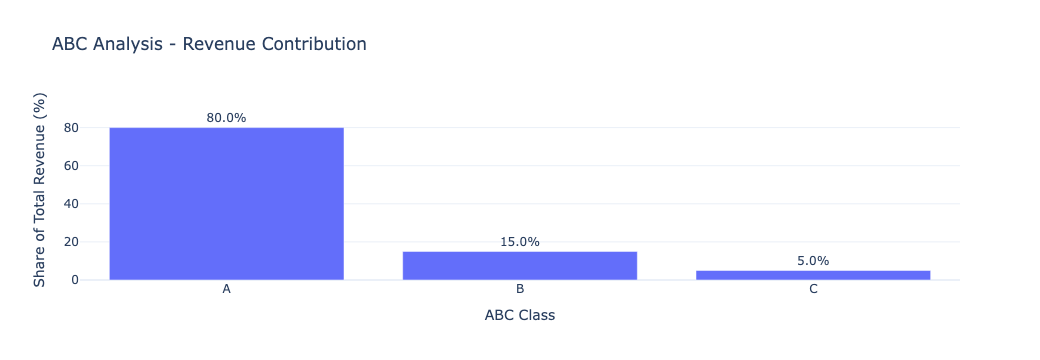

In [16]:

import plotly.express as px

fig = px.bar(
    abc_summary,
    x="ABC_Class",
    y="Revenue_Share_%",
    text="Revenue_Share_%",
    category_orders={"ABC_Class": ["A", "B", "C"]},
    title="ABC Analysis - Revenue Contribution"
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig.update_layout(
    xaxis_title="ABC Class",
    yaxis_title="Share of Total Revenue (%)",
    template="plotly_white"
)

fig.show()


In [17]:

# Set the reference date to one day after the last transaction
reference_date = df_sales["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = (
    df_sales.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# Display descriptive statistics
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


,CustomerID,Recency,Frequency,Monetary
0,A00001,1,205,116492.930000
1,A00001-01,4,7,2764.960000
2,A00003,1,297,234392.269999
3,A00004,63,2,2871.000000
4,A00005,275,13,5561.850000


,Recency,Frequency,Monetary
count,1201.000000,1201.000000,1.201000e+03
mean,88.372190,39.523730,2.462944e+04
std,113.454773,70.673142,7.147849e+04
min,1.000000,1.000000,2.350000e+00
25%,4.000000,3.000000,8.705800e+02
50%,28.000000,10.000000,4.328520e+03
75%,122.000000,43.000000,1.899501e+04
max,364.000000,611.000000,1.482348e+06


In [18]:

# Assign RFM scores from 1 to 5 using percentile ranks
rfm["R_Score"] = np.ceil(
    (1 - rfm["Recency"].rank(pct=True, method="average")) * 5
).clip(1, 5).astype(int)

rfm["F_Score"] = np.ceil(
    rfm["Frequency"].rank(pct=True, method="average") * 5
).clip(1, 5).astype(int)

rfm["M_Score"] = np.ceil(
    rfm["Monetary"].rank(pct=True, method="average") * 5
).clip(1, 5).astype(int)

# Combine the three scores
rfm["RFM_Score"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

display(rfm.head())


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,A00001,1,205,116492.930000,5,5,5,15
1,A00001-01,4,7,2764.960000,4,3,3,10
2,A00003,1,297,234392.269999,5,5,5,15
3,A00004,63,2,2871.000000,2,1,3,6
4,A00005,275,13,5561.850000,1,3,3,7


In [19]:

# Define customer segments based on RFM scores
def assign_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["F_Score"] >= 4 and row["M_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    else:
        return "Other Customers"

# Apply segmentation rules
rfm["Segment"] = rfm.apply(assign_segment, axis=1)

# Summarize customer segments
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Total_Revenue=("Monetary", "sum"),
        Avg_Frequency=("Frequency", "mean")
    )
    .reset_index()
)

display(segment_summary.round(2))


,Segment,Customer_Count,Total_Revenue,Avg_Frequency
0,At Risk,74,466911.75,10.84
1,Champions,308,21199551.20,116.18
2,Loyal Customers,163,4934084.27,46.87
3,Other Customers,656,2979413.02,4.94


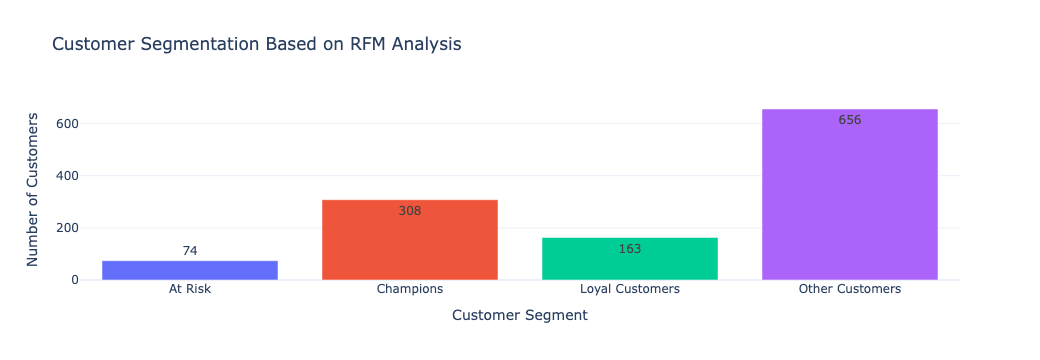

In [20]:

# Visualize the number of customers in each RFM segment
fig = px.bar(
    segment_summary,
    x="Segment",
    y="Customer_Count",
    color="Segment",
    text="Customer_Count",
    title="Customer Segmentation Based on RFM Analysis"
)

fig.update_layout(
    xaxis_title="Customer Segment",
    yaxis_title="Number of Customers",
    showlegend=False,
    template="plotly_white"
)

fig.show()
